# Module 1 · Partie 3 : La régression linéaire multivariée

> Sources : slides *Linear, Ridge, Lasso regressions* (« Multivariate linear regression », « Estimation of regression coefficients », « R: multivariate linear regression »), syllabus *module1.pdf* §3.2, §3.4, §3.7, résolution *Module 1 - Lactoferrin* §6-7.

### Objectifs d'apprentissage
1. Écrire la régression multivariée sous **forme matricielle** $y = X\beta + e$ et comprendre la matrice $X$ (colonne de 1 pour l'intercept).
2. Dériver et calculer **à la main** l'estimateur des moindres carrés ordinaires (MCO / *OLS*) $\hat\beta = (X'X)^{-1}X'y$ et le comparer à `lm()`.
3. Comprendre pourquoi ajouter des variables augmente toujours le R² et ce qu'est le **sur-ajustement** (*overfitting*) ; distinguer **calibration** et **validation**.
4. Diagnostiquer la **colinéarité** (corrélations entre explicatives, singularités, coefficients instables et non significatifs).
5. Appliquer tout cela aux **10 points spectraux** les plus corrélés à la lactoferrine.
6. Connaître les **précautions** d'usage et savoir **créer de nouvelles variables** (polynômes, interactions).

### Prérequis
Partie 2 (régression univariée, `lm`, analyse des résidus, log10).

### Sommaire
- 3.1 Du modèle univarié au modèle multivarié
- 3.2 Estimation des coefficients : les moindres carrés ordinaires (OLS)
- 3.3 Qualité d'ajustement, MSE et sur-ajustement
- 3.4 Exemple « méthane » : la colinéarité parfaite (données simulées)
- 3.5 Application : lactoferrine et 10 points spectraux
- 3.6 La colinéarité dans les données spectrales
- 3.7 Précautions
- 3.8 Création de nouvelles variables (polynômes, interactions)
- Récapitulatif

In [1]:
suppressPackageStartupMessages({
  library(knitr)      # kable()
  library(corrplot)   # corrplot()
  library(car)        # vif() (complément)
})
options(repr.plot.width = 10, repr.plot.height = 6)

---
## 3.1 Du modèle univarié au modèle multivarié

Dans un contexte de Data Mining / Machine Learning, le nombre de variables explicatives est **toujours supérieur à 1**. L'analyse univariée reste utile pour se faire une idée du lien entre y et **chaque** explicative (partie 2), mais l'information est souvent **disséminée** dans plusieurs variables.

Les slides présentent plusieurs « concepts » de régression :

| Modèle | Écriture | Dans ce cours |
|---|---|---|
| **Univarié** | un $y$, un $x$ : $y = a + b\,x + e$ | partie 2 |
| **Multivarié** (*multiple*) | un $y$, plusieurs $x$ : $y = b_1 x_1 + b_2 x_2 + \dots + b_{q} x_{q} + e$ | **cette partie** |
| **Multi-trait** | plusieurs $y$ (matrice $Y$, colonnes $y_{\cdot,1}\dots y_{\cdot,j}$) expliqués par les mêmes $x$ | mentionné dans les slides |

**Intérêts de la régression** (slides) : (1) **connaître les relations** entre le trait étudié (y) et des variables explicatives (x) ; (2) **utiliser la prédiction** pour développer des outils de gestion ou d'analyse. Intérêt dans de nombreux domaines scientifiques.

### 3.1.1 La forme matricielle
La régression multivariée généralise la régression univariée :

$$\boxed{y = X\beta + e}$$

- $y$ : vecteur ($n \times 1$) des observations de la variable à expliquer ;
- $\beta$ : vecteur ($(q+1) \times 1$) des coefficients de régression $b_0, b_1, \dots, b_q$ ;
- $X$ : **matrice d'incidence** ($n \times (q+1)$) qui relie $y$ et $\beta$ ; sa **première colonne de 1** porte l'intercept $b_0$ ;
- $e$ : vecteur ($n \times 1$) des résidus.

Avec $q$ variables et $n$ observations :

$$
\begin{bmatrix} y_1\\ y_2\\ y_3\\ \vdots\\ y_n \end{bmatrix}
=
\begin{bmatrix}
1 & x_{1,1} & x_{1,2} & \cdots & x_{1,q}\\
1 & x_{2,1} & x_{2,2} & \cdots & x_{2,q}\\
1 & x_{3,1} & x_{3,2} & \cdots & x_{3,q}\\
\vdots & \vdots & \vdots & \ddots & \vdots\\
1 & x_{n,1} & x_{n,2} & \cdots & x_{n,q}
\end{bmatrix}
\begin{bmatrix} b_0\\ b_1\\ b_2\\ \vdots\\ b_q \end{bmatrix}
+
\begin{bmatrix} e_1\\ e_2\\ e_3\\ \vdots\\ e_n \end{bmatrix}
$$

Ligne $i$ : $y_i = b_0 + b_1 x_{i,1} + b_2 x_{i,2} + \dots + b_q x_{i,q} + e_i$.

**Interprétation géométrique** (slides) : avec 2 explicatives, on ne cherche plus une droite mais un **plan** dans l'espace $(x_1, x_2, y)$ qui minimise la distance entre les observations et les valeurs prédites ; avec $q$ variables, un **hyperplan**.

> **Complément — interprétation des coefficients** : en multivarié, $b_j$ est l'effet de $x_j$ sur $y$ **toutes les autres variables du modèle étant fixées**. C'est pour ça qu'un même $x_j$ peut avoir un coefficient très différent selon les autres variables présentes (cf. 3.4).

---
## 3.2 Estimation des coefficients : les moindres carrés ordinaires

### 3.2.1 Dérivation
Comme en univarié, on minimise la somme des carrés des résidus $e'e = (y - X\beta)'(y - X\beta)$ :

$$\min_\beta \; e^2 = (y - X\beta)^2 \qquad \Longrightarrow \qquad \frac{\partial (y - X\beta)^2}{\partial \beta} = 0$$

Développons (le cours donne directement le résultat ; voici le détail) :
$$S(\beta) = (y - X\beta)'(y - X\beta) = y'y - 2\beta'X'y + \beta'X'X\beta$$
$$\frac{\partial S}{\partial \beta} = -2X'y + 2X'X\beta = 0 \quad\Longrightarrow\quad X'X\,\beta = X'y \quad \text{(équations normales)}$$

$$\boxed{\hat\beta = (X'X)^{-1}X'y}$$

C'est l'estimateur des **moindres carrés ordinaires** (*ordinary least squares*, **OLS**). Avec une seule variable, on retrouve exactement $a$ et $b$ de la partie 2.

> **Attention** (slides) : « *The inversion can be sometimes problematic* ». $(X'X)^{-1}$ n'existe que si les colonnes de $X$ sont **linéairement indépendantes** : impossible en cas de **colinéarité parfaite** ou si $n < q+1$. Quand les colonnes sont *presque* dépendantes, l'inversion est **numériquement instable** et les coefficients explosent.

> **Données standardisées** (slides) : si $x$ et $y$ sont **centrées** (moyenne retirée), l'intercept disparaît et la pente univariée $\frac{\sum (x_i - \bar x)(y_i - \bar y)}{\sum (x_i-\bar x)^2}$ devient simplement $\dfrac{\sum xy}{\sum x^2}$ — c'est $(X'X)^{-1}X'y$ avec une seule colonne.

### 3.2.2 Calcul matriciel dans R

> **Fonctions R d'algèbre matricielle**
>
> | Fonction | Rôle |
> |---|---|
> | `cbind(1, X)` | ajouter une colonne de 1 (intercept) |
> | `t(X)` | transposée $X'$ |
> | `A %*% B` | produit matriciel (`*` = produit élément par élément !) |
> | `crossprod(X)` / `crossprod(X, y)` | $X'X$ / $X'y$ (plus rapide) |
> | `solve(A)` | inverse $A^{-1}$ ; `solve(A, b)` résout $A\beta = b$ (plus stable) |
> | `kappa(A)` | **conditionnement** : très grand ⇒ matrice presque singulière |
> | `qr(X)$rank` | rang de $X$ (nombre de colonnes indépendantes) |

On reprend le jeu **méthane simulé** de la partie 2 (mêmes paramètres, même `set.seed`).

In [2]:
# ---- Jeu "méthane" simulé (identique à la partie 2) ----
set.seed(2027)
n <- 20
FA4_6   <- rnorm(n, 4.6, 0.55)
FA7_9   <- rnorm(n, 0.95, 0.12) + 0.08 * (FA4_6 - 4.6)
FA10_12 <- rnorm(n, 4.9, 0.7)
FA13_15 <- rnorm(n, 11.8, 1.1)
FA16_18 <- 100 - FA4_6 - FA7_9 - FA10_12 - FA13_15      # somme = 100 %
CH4 <- -700 + 90 * FA4_6 + 600 * FA7_9 + 12 * FA10_12 + 10 * FA13_15 + rnorm(n, 0, 70)
methane <- data.frame(FA4_6, FA7_9, FA10_12, FA13_15, FA16_18, CH4)
rowSums(methane[, 1:5])[1:5]       # vérification : 100 % pour chaque vache

[1] 100 100 100 100 100

In [3]:
# Modèle à 2 explicatives : CH4 ~ FA4_6 + FA7_9
y <- methane$CH4
X <- cbind(1, methane$FA4_6, methane$FA7_9)          # matrice d'incidence n x 3
colnames(X) <- c("(Intercept)", "FA4_6", "FA7_9")
head(X, 3)

beta_inv   <- solve(t(X) %*% X) %*% t(X) %*% y       # formule du cours
beta_solve <- solve(crossprod(X), crossprod(X, y))   # même chose, plus stable
beta_lm    <- coef(lm(CH4 ~ FA4_6 + FA7_9, data = methane))

cbind(formule = beta_inv[, 1], solve = beta_solve[, 1], lm = beta_lm)

(Intercept),FA4_6,FA7_9
1,4.085817,1.0518631
1,4.218375,0.9469377
1,4.298630,0.9571676


,formule,solve,lm
(Intercept),-477.18322,-477.18322,-477.18322
FA4_6,72.04129,72.04129,72.04129
FA7_9,620.68242,620.68242,620.68242


In [4]:
# Données centrées : b = sum(xy) / sum(x^2) en univarié
xc <- methane$FA4_6 - mean(methane$FA4_6)
yc <- y - mean(y)
c(b_centre = sum(xc * yc) / sum(xc^2),
  b_lm     = unname(coef(lm(CH4 ~ FA4_6, data = methane))[2]))

b_centre     b_lm 
123.9785 123.9785

### Exercice 3.1 : OLS à la main avec 4 variables
Construis la matrice $X$ (avec la colonne de 1) pour le modèle `CH4 ~ FA4_6 + FA7_9 + FA10_12 + FA13_15`, calcule $\hat\beta = (X'X)^{-1}X'y$, puis les valeurs prédites $\hat y = X\hat\beta$ et les résidus. Compare à `lm()`.

*Astuce :* `as.matrix(methane[, 1:4])` récupère les 4 colonnes en une fois.

In [5]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
X4 <- cbind(1, as.matrix(methane[, 1:4]))
b4 <- solve(t(X4) %*% X4) %*% t(X4) %*% y
yhat4 <- X4 %*% b4
e4 <- y - yhat4
m4 <- lm(CH4 ~ FA4_6 + FA7_9 + FA10_12 + FA13_15, data = methane)
cbind(main = b4[, 1], lm = coef(m4))
all.equal(as.vector(yhat4), unname(fitted(m4)))
```

Les coefficients, les prédictions et donc les résidus sont identiques : `lm()` résout les mêmes équations normales (en interne via une décomposition QR, plus stable que l'inversion directe).

</details>

---
## 3.3 Qualité d'ajustement, MSE et sur-ajustement

Comme en univarié, on évalue l'ajustement par le **R²** et le **RMSE**. Mais ici le calcul du MSE tient compte du **nombre de variables explicatives** $p$ :

$$MSE = \frac{1}{n-p}\sum_{i=1}^n (y_i - \hat y_i)^2 = \frac{1}{n-p}\sum_{i=1}^n e_i^2$$

> **Attention — notation** : dans le syllabus, $p$ désigne le nombre de **paramètres estimés**. Avec un intercept et $q$ variables, R divise par $n - q - 1$ (`df.residual`) : c'est le carré du *Residual standard error*.

In [6]:
m4 <- lm(CH4 ~ FA4_6 + FA7_9 + FA10_12 + FA13_15, data = methane)
MSE4 <- sum(resid(m4)^2) / m4$df.residual
c(df = m4$df.residual, MSE = MSE4, RMSE = sqrt(MSE4), sigma_R = summary(m4)$sigma)

df        MSE       RMSE    sigma_R 
  15.00000 5790.73969   76.09691   76.09691

### 3.3.1 Ajouter des variables augmente toujours le R²… même inutiles
Si l'on ajoute des explicatives (liées à y), le $R^2$ augmente et le RMSE diminue. Mais **même des variables sans aucun lien avec y** font augmenter le $R^2$ de calibration ! À un moment, on finit par expliquer une variabilité **propre au jeu de données** et non générale : c'est le **sur-ajustement** (*overfitting*, *over-adjustment*).

nb_bruit,R2,R2_adj
0,0.699,0.619
1,0.744,0.652
2,0.744,0.625
3,0.757,0.616
4,0.775,0.611
5,0.781,0.583
6,0.807,0.593
7,0.807,0.543
8,0.862,0.625
9,0.863,0.566


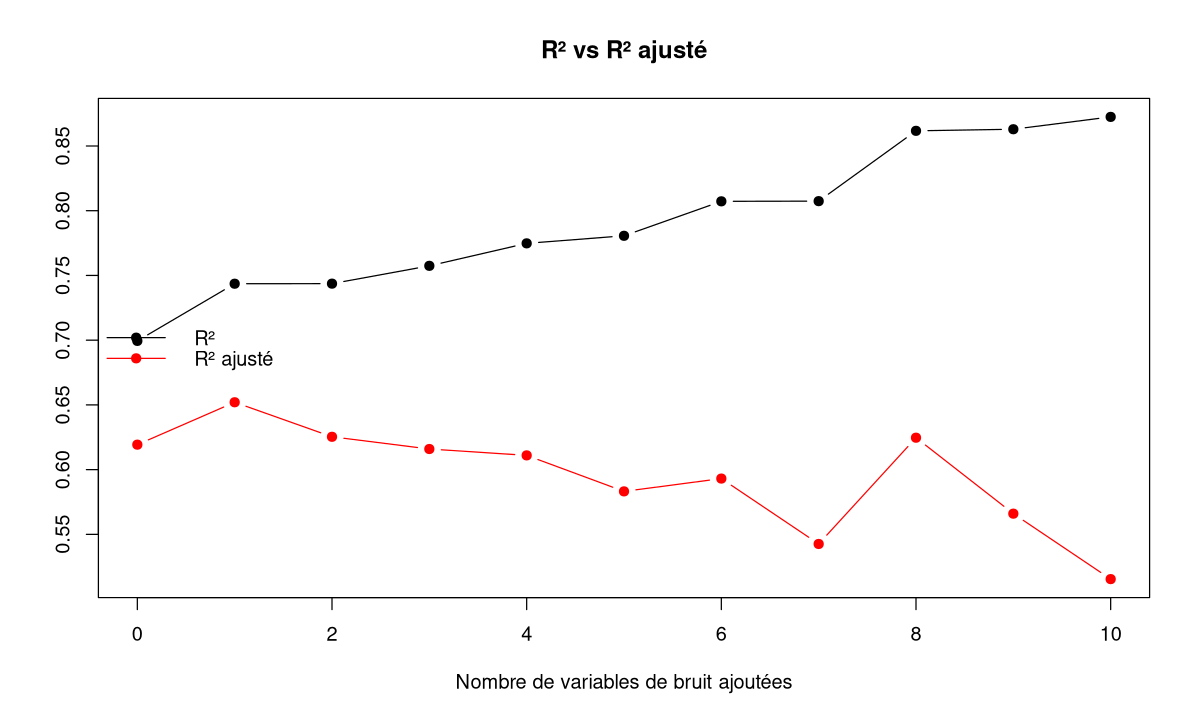

In [7]:
# On ajoute à m4 des variables de pur bruit et on suit R2 et R2 ajusté
set.seed(42)
bruit <- matrix(rnorm(n * 10), n, 10)
res <- t(sapply(0:10, function(k) {
  m <- if (k == 0) m4 else lm(methane$CH4 ~ as.matrix(methane[, 1:4]) + bruit[, 1:k])
  c(nb_bruit = k, R2 = summary(m)$r.squared, R2_adj = summary(m)$adj.r.squared)
}))
round(res, 3)
matplot(res[, 1], res[, 2:3], type = "b", pch = 19, lty = 1, col = c("black", "red"),
        xlab = "Nombre de variables de bruit ajoutées", ylab = "", main = "R² vs R² ajusté")
legend("left", c("R²", "R² ajusté"), col = c("black", "red"), lty = 1, pch = 19, bty = "n")

Le $R^2$ grimpe vers 1 alors que les variables ajoutées sont du **bruit pur** ; le $R^2$ ajusté, lui, stagne ou chute.

### 3.3.2 Sous-ajustement, bon ajustement, sur-ajustement (Fig. 6 du syllabus)
Pour **détecter** le sur-ajustement, le modèle développé doit être testé sur un **jeu de données indépendant** : c'est la **validation** (étape 5 du processus KDD). On distingue :
- l'erreur de **calibration** (sur les données ayant servi à construire le modèle) : RMSEC ;
- l'erreur de **validation / prédiction** (sur des données nouvelles) : **RMSEP** (*root mean square error of prediction*).

Illustration avec une **régression polynomiale** (cf. 3.8) de degré croissant :

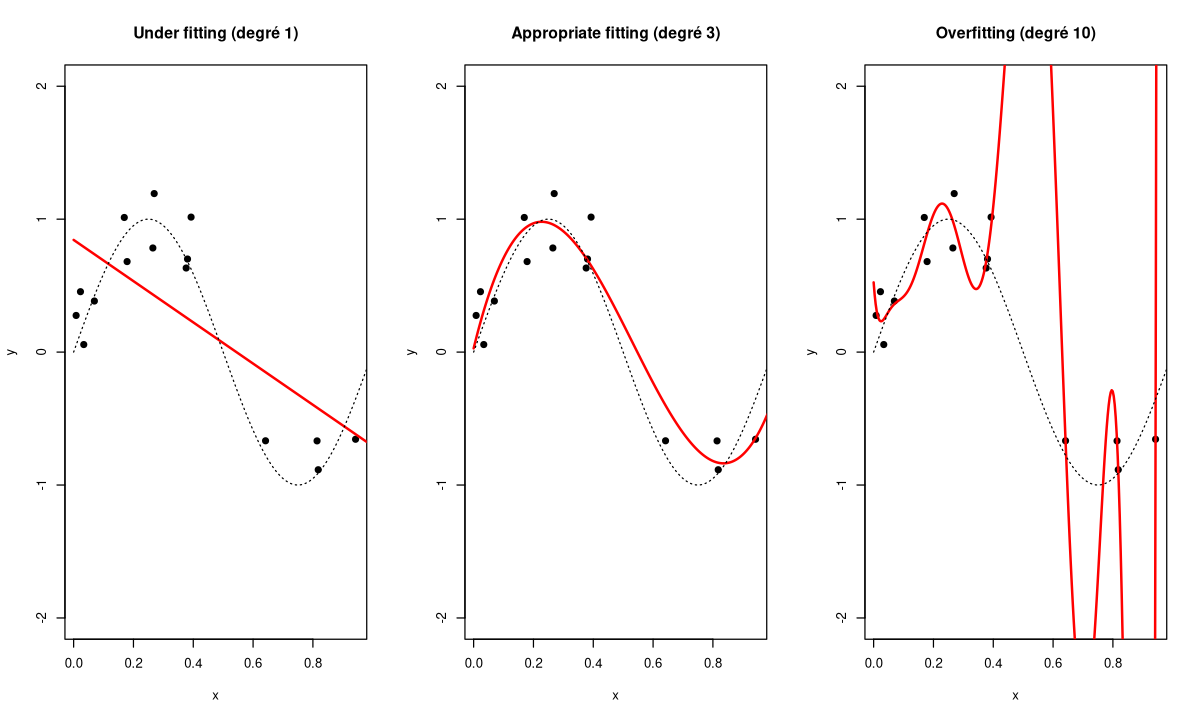

In [8]:
set.seed(12)
f_vraie <- function(x) sin(2 * pi * x)                 # relation "vraie" (inconnue en pratique)
x_cal <- runif(15); y_cal <- f_vraie(x_cal) + rnorm(15, 0, 0.25)   # calibration
x_val <- runif(200, min(x_cal), max(x_cal)); y_val <- f_vraie(x_val) + rnorm(200, 0, 0.25) # validation indépendante

grille <- seq(0, 1, length.out = 300)
par(mfrow = c(1, 3))
for (d in c(1, 3, 10)) {
  m <- lm(y_cal ~ poly(x_cal, d, raw = TRUE))
  pred <- cbind(1, outer(grille, 1:d, "^")) %*% coef(m)
  plot(x_cal, y_cal, pch = 19, ylim = c(-2, 2), xlab = "x", ylab = "y",
       main = c("1" = "Under fitting (degré 1)", "3" = "Appropriate fitting (degré 3)",
                "10" = "Overfitting (degré 10)")[as.character(d)])
  lines(grille, pred, col = "red", lwd = 2)
  lines(grille, f_vraie(grille), lty = 3)
}
par(mfrow = c(1, 1))

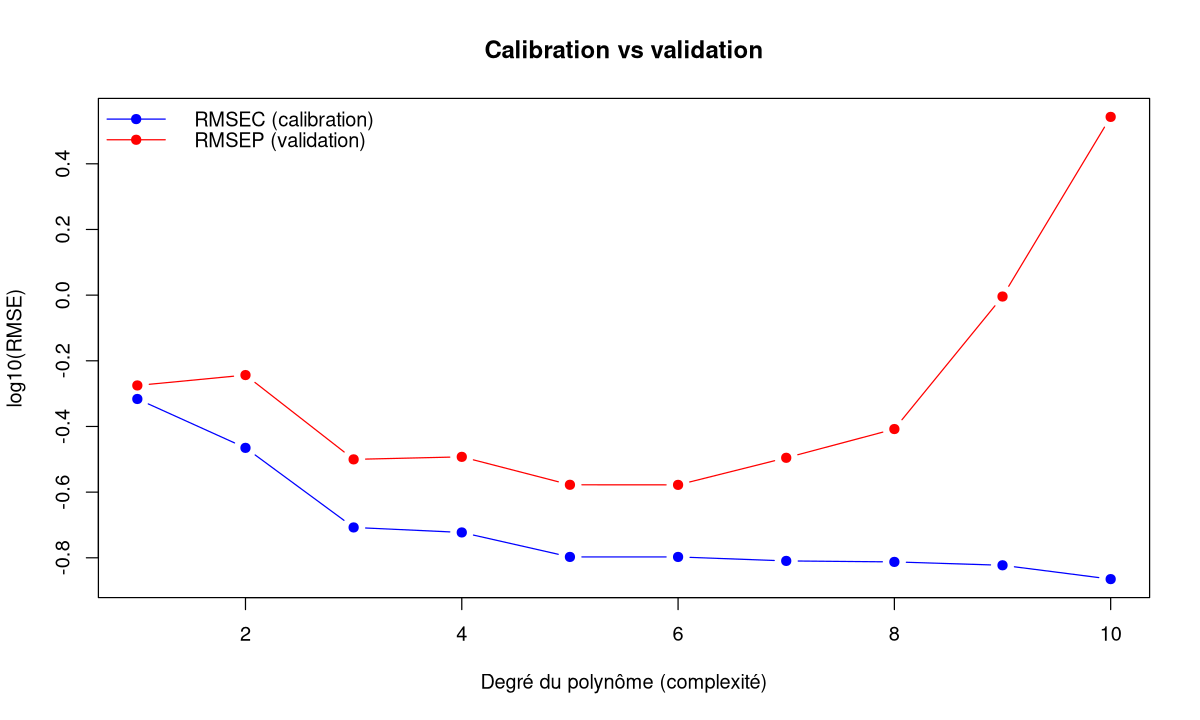

In [9]:
# Erreurs de calibration et de validation selon la complexité
rmse <- function(obs, pred) sqrt(mean((obs - pred)^2))
deg <- 1:10
err <- t(sapply(deg, function(d) {
  m <- lm(y_cal ~ poly(x_cal, d, raw = TRUE))
  p_val <- cbind(1, outer(x_val, 1:d, "^")) %*% coef(m)
  c(RMSEC = rmse(y_cal, fitted(m)), RMSEP = rmse(y_val, p_val))
}))
matplot(deg, log10(err), type = "b", pch = 19, lty = 1, col = c("blue", "red"),
        xlab = "Degré du polynôme (complexité)", ylab = "log10(RMSE)",
        main = "Calibration vs validation")
legend("topleft", c("RMSEC (calibration)", "RMSEP (validation)"),
       col = c("blue", "red"), lty = 1, pch = 19, bty = "n")

L'erreur de **calibration** diminue toujours avec la complexité ; l'erreur de **validation** passe par un **minimum** (bon ajustement) puis **explose** (sur-ajustement). La validation (et la validation croisée) est l'objet du **module 2** ; les régressions pénalisées (partie 6) sont une autre arme contre le sur-ajustement.

### Exercice 3.2 : quel degré choisir ?
À partir de la matrice `err`, trouve le degré qui minimise l'erreur de validation et celui qui minimise l'erreur de calibration. Que conclus-tu ?

In [10]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
which.min(err[, "RMSEP"])   # degré optimal en validation (5 ici)
which.min(err[, "RMSEC"])   # toujours le degré maximal (10)
round(err, 3)
```

Si l'on choisissait le modèle sur ses performances de **calibration**, on prendrait toujours le plus complexe — donc le plus sur-ajusté. Seule une évaluation sur des **données indépendantes** permet de choisir la bonne complexité.

</details>

---
## 3.4 Exemple « méthane » : la colinéarité parfaite

> **Attention** : données **simulées** (cf. partie 2). Dans les slides (données réelles, n = 20), les valeurs sont : modèle complet $R^2 = 0.62$, $R^2_{adj} = 0.52$, RMSE = 81.21 g/jour.

### 3.4.1 « Can we improve the results ? »
Les 5 modèles univariés donnent des $R^2$ modestes. Idée naturelle : mettre **les 5 groupes d'acides gras ensemble** dans un modèle multivarié.

In [11]:
FA <- as.matrix(methane)               # colonnes 1-5 : acides gras ; colonne 6 : CH4
reg_FA <- lm(FA[, 6] ~ FA[, 1:5])      # même écriture que sur la slide
summary(reg_FA)


Call:
lm(formula = FA[, 6] ~ FA[, 1:5])

Residuals:
     Min       1Q   Median       3Q      Max 
-196.322  -22.629    8.996   41.329   97.837 

Coefficients: (1 not defined because of singularities)
                 Estimate Std. Error t value Pr(>|t|)   
(Intercept)      -695.005    297.663  -2.335  0.03386 * 
FA[, 1:5]FA4_6     58.441     34.683   1.685  0.11267   
FA[, 1:5]FA7_9    753.140    188.420   3.997  0.00117 **
FA[, 1:5]FA10_12   49.529     24.095   2.056  0.05767 . 
FA[, 1:5]FA13_15   -8.036     15.838  -0.507  0.61926   
FA[, 1:5]FA16_18       NA         NA      NA       NA   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 76.1 on 15 degrees of freedom
Multiple R-squared:  0.6994,	Adjusted R-squared:  0.6193 
F-statistic: 8.727 on 4 and 15 DF,  p-value: 0.0007587


**« What is the problem ? »** La sortie indique `Coefficients: (1 not defined because of singularities)` et la 5e variable a un coefficient **NA**.

**Explication** : les 5 groupes d'acides gras sont exprimés en **% de la matière grasse** et leur **somme vaut 100** pour chaque vache. La 5e colonne est donc une **combinaison linéaire exacte** des autres (et de la colonne de 1) :
$$FA16\text{-}18 = 100 - FA4\text{-}6 - FA7\text{-}9 - FA10\text{-}12 - FA13\text{-}15$$
→ **colinéarité parfaite** : $X'X$ n'est pas inversible. `lm()` le détecte et élimine la variable redondante (NA).

In [12]:
X5 <- cbind(1, FA[, 1:5])
qr(X5)$rank                 # rang 5 alors que X5 a 6 colonnes
# L'inversion "à la main" échoue :
tryCatch(solve(t(X5) %*% X5), error = function(e) cat("Erreur :", conditionMessage(e), "\n"))

[1] 5

Erreur : system is computationally singular: reciprocal condition number = 2.75415e-20 


### 3.4.2 « Which solution ? » → considérer 4 traits
Puisqu'une variable est redondante, on n'en garde que **4 sur 5**. Il y a 5 façons de le faire (tableau de la slide) :

| Modèle | FA[,1] | FA[,2] | FA[,3] | FA[,4] | FA[,5] |
|---|---|---|---|---|---|
| 1 | X | X | X | X |   |
| 2 | X | X | X |   | X |
| 3 | X | X |   | X | X |
| 4 | X |   | X | X | X |
| 5 |   | X | X | X | X |

In [13]:
combis <- list(c(1, 2, 3, 4), c(1, 2, 3, 5), c(1, 2, 4, 5), c(1, 3, 4, 5), c(2, 3, 4, 5))
modeles <- lapply(combis, function(j) lm(FA[, 6] ~ FA[, j]))

perf <- t(sapply(modeles, function(m) {
  s <- summary(m)
  c(R2 = s$r.squared, R2_adj = s$adj.r.squared, RMSE = s$sigma)
}))
rownames(perf) <- paste("Modèle", 1:5)
kable(perf, digits = 2)



|         |  R2| R2_adj| RMSE|
|:--------|---:|------:|----:|
|Modèle 1 | 0.7|   0.62| 76.1|
|Modèle 2 | 0.7|   0.62| 76.1|
|Modèle 3 | 0.7|   0.62| 76.1|
|Modèle 4 | 0.7|   0.62| 76.1|
|Modèle 5 | 0.7|   0.62| 76.1|

**Performances de calibration identiques** pour les 5 modèles ! (dans la slide : R² 0.62, R² ajusté 0.52, RMSE 81.21 pour les 5). C'est logique : avec la colonne de 1, n'importe quel choix de 4 colonnes sur 5 engendre **exactement le même espace** de prédictions.

In [14]:
# ... mais des coefficients (et donc des interprétations) très différents :
coefs <- lapply(seq_along(modeles), function(i) {
  ct <- summary(modeles[[i]])$coefficients[, c(1, 2, 4)]
  rownames(ct) <- c("(Intercept)", paste0("FA", combis[[i]]))
  round(ct, 3)
})
names(coefs) <- paste("Modèle", 1:5)
coefs

,Estimate,Std. Error,Pr(>|t|)
(Intercept),-695.005,297.663,0.034
FA1,58.441,34.683,0.113
FA2,753.140,188.420,0.001
FA3,49.529,24.095,0.058
FA4,-8.036,15.838,0.619
,Estimate,Std. Error,Pr(>|t|)
(Intercept),-1498.597,1416.204,0.307
FA1,66.477,33.186,0.064
FA2,761.176,192.147,0.001
FA3,57.565,30.232,0.076


**« But different interpretation based on the model used »** : selon le modèle, un même acide gras a un coefficient positif ou négatif, significatif ou non ; l'intercept varie énormément. Par exemple dans le modèle 4 (sans FA7-9), tous les coefficients des acides gras sont **négatifs** (et l'intercept énorme) : augmenter un groupe à composition constante revient à **diminuer** FA7-9, qui est le groupe le plus lié au méthane.

> **À retenir** : en présence de colinéarité, les **prédictions** peuvent rester bonnes, mais **l'interprétation des coefficients individuels n'a plus de sens**. C'est exactement le problème que la **régression Ridge** (partie 6) cherche à résoudre.

**Rappel — les 5 modèles univariés** (tableau de la slide : R², R² ajusté, RMSE) :

In [15]:
uni <- t(sapply(1:5, function(j) {
  s <- summary(lm(FA[, 6] ~ FA[, j]))
  c(R2 = s$r.squared, R2_adj = s$adj.r.squared, RMSE = s$sigma)
}))
rownames(uni) <- colnames(FA)[1:5]
kable(uni, digits = 2)



|        |   R2| R2_adj|   RMSE|
|:-------|----:|------:|------:|
|FA4_6   | 0.36|   0.33| 101.07|
|FA7_9   | 0.52|   0.49|  88.21|
|FA10_12 | 0.01|  -0.04| 126.04|
|FA13_15 | 0.01|  -0.04| 125.86|
|FA16_18 | 0.07|   0.02| 122.00|

### Exercice 3.3 : mêmes prédictions ?
1. Vérifie que les **valeurs prédites** des modèles 1 et 5 sont identiques (`all.equal`).
2. Dans le modèle 1, exprime le coefficient de FA[,5] « caché » : que vaudrait-il si on réécrivait le modèle 1 en fonction des colonnes du modèle 2 ? (Indice : remplace FA4 par 100 − FA1 − FA2 − FA3 − FA5 et compare l'intercept et les coefficients du modèle 2.)

In [16]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
all.equal(fitted(modeles[[1]]), fitted(modeles[[5]]))   # TRUE

c1 <- coef(modeles[[1]]); c2 <- coef(modeles[[2]])
# Modèle 1 : b0 + b1 FA1 + b2 FA2 + b3 FA3 + b4 FA4, avec FA4 = 100 - FA1 - FA2 - FA3 - FA5
# = (b0 + 100 b4) + (b1 - b4) FA1 + (b2 - b4) FA2 + (b3 - b4) FA3 - b4 FA5
reecrit <- c(c1[1] + 100 * c1[5], c1[2] - c1[5], c1[3] - c1[5], c1[4] - c1[5], -c1[5])
cbind(modele1_reecrit = reecrit, modele2 = c2)
```

Les deux jeux de coefficients sont **identiques** : les modèles sont la même équation écrite dans deux « bases » différentes. D'où les mêmes performances mais des coefficients différents.

</details>

---
## 3.5 Application : lactoferrine et 10 points spectraux

L'utilisation d'**un seul** point spectral est trop restrictive : l'information est disséminée dans tout le spectre. Une sélection **intuitive** : prendre les **10 points spectraux** ayant la plus forte corrélation (en valeur absolue) avec la lactoferrine.

In [17]:
lactoferrin <- read.table(file = "../lactoferrin.csv", sep = ";")
y <- as.matrix(lactoferrin[, 1062])

correlation <- cor(lactoferrin[, 2:1062])[1:1060, 1061]   # méthode de la résolution
ordercorrelation <- order(abs(correlation))

corr3 <- correlation[ordercorrelation[1051:1060]]          # les dix plus fortes corrélations
kable(t(corr3), digits = 2)                                # t() = transposer



|  V608|  V679| V716| V710| V209| V715| V711| V714| V712| V713|
|-----:|-----:|----:|----:|----:|----:|----:|----:|----:|----:|
| -0.23| -0.23| 0.27|  0.3| 0.32| 0.36| 0.44| 0.46| 0.51| 0.51|

Parmi ces 10 points, 7 sont **adjacents** (V710 à V716 : la même bande d'absorption). Deux corrélations sont **négatives** (V608, V679) : c'est pour ça qu'on classe sur `abs(correlation)`.

On construit la matrice $X$ des 10 explicatives (n × 10). Le `+1` compense toujours la colonne d'identifiant.

In [18]:
x <- lactoferrin[, ordercorrelation[1051:1060] + 1]
x <- as.matrix(x)
kable(head(x), digits = 3)
dim(x)



|   V608|   V679|   V716|   V710|   V209|   V715|   V711|   V714|   V712|   V713|
|------:|------:|------:|------:|------:|------:|------:|------:|------:|------:|
| -0.087| -0.003| -0.135| -0.100| -0.035| -0.156| -0.138| -0.175| -0.173| -0.185|
| -0.070|  0.012| -0.158| -0.093| -0.038| -0.179| -0.139| -0.198| -0.185| -0.205|
| -0.092| -0.042| -0.136| -0.129| -0.036| -0.154| -0.156| -0.170| -0.177| -0.181|
| -0.399| -0.031| -0.137| -0.066| -0.034| -0.154| -0.115| -0.169| -0.157| -0.175|
| -0.103|  0.067| -0.132| -0.084| -0.033| -0.151| -0.125| -0.168| -0.162| -0.176|
|  0.145| -0.018| -0.162| -0.130| -0.037| -0.186| -0.170| -0.208| -0.207| -0.220|

[1] 178  10

### 3.5.1 Régression sur y brut : `reg2`
Avec `lm(y ~ x)` où `x` est une **matrice**, R crée une variable par colonne (nommées `xV608`, `xV679`…).


	Shapiro-Wilk normality test

data:  resid(reg2)
W = 0.80596, p-value = 4.124e-14


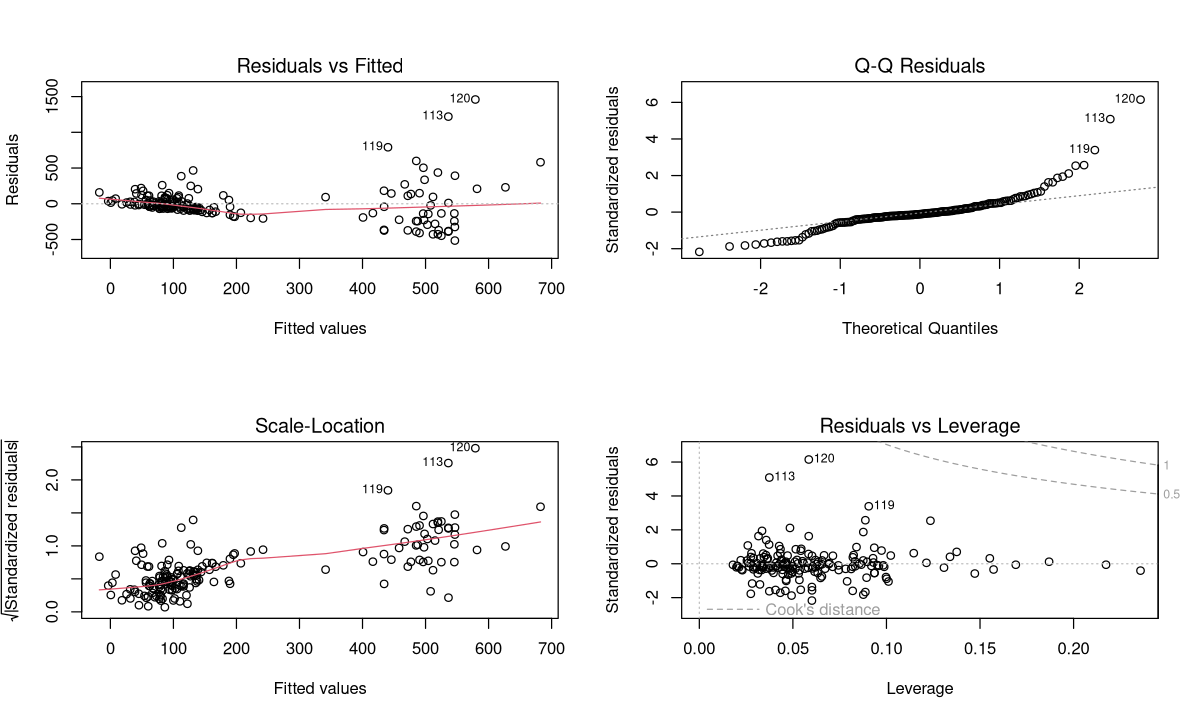

In [19]:
reg2 <- lm(y ~ x)
par(mfrow = c(2, 2)); plot(reg2); par(mfrow = c(1, 1))
shapiro.test(resid(reg2))

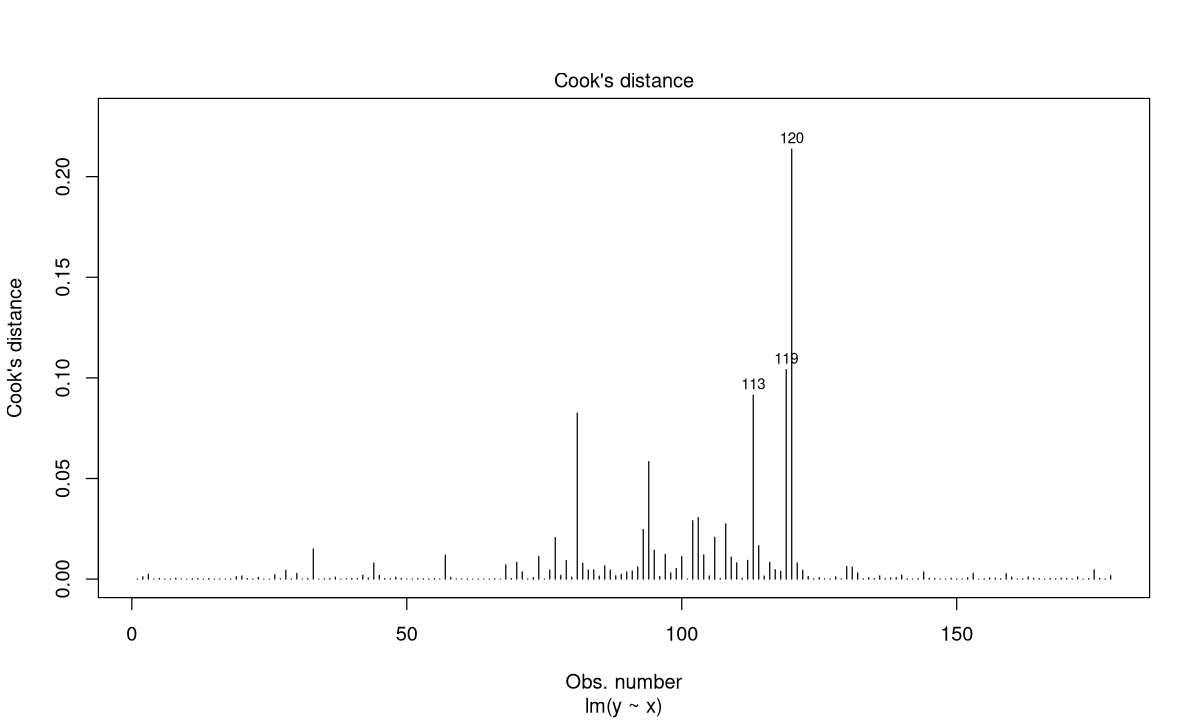

In [20]:
plot(reg2, which = 4)

Comme en univarié, les résidus ne remplissent **pas** les conditions (W = 0.806, p ≈ 4e-14 ; hétéroscédasticité). La transformation **log10** est nécessaire.

### 3.5.2 Régression sur log10(y) : `reg2b`


	Shapiro-Wilk normality test

data:  resid(reg2b)
W = 0.99379, p-value = 0.6576


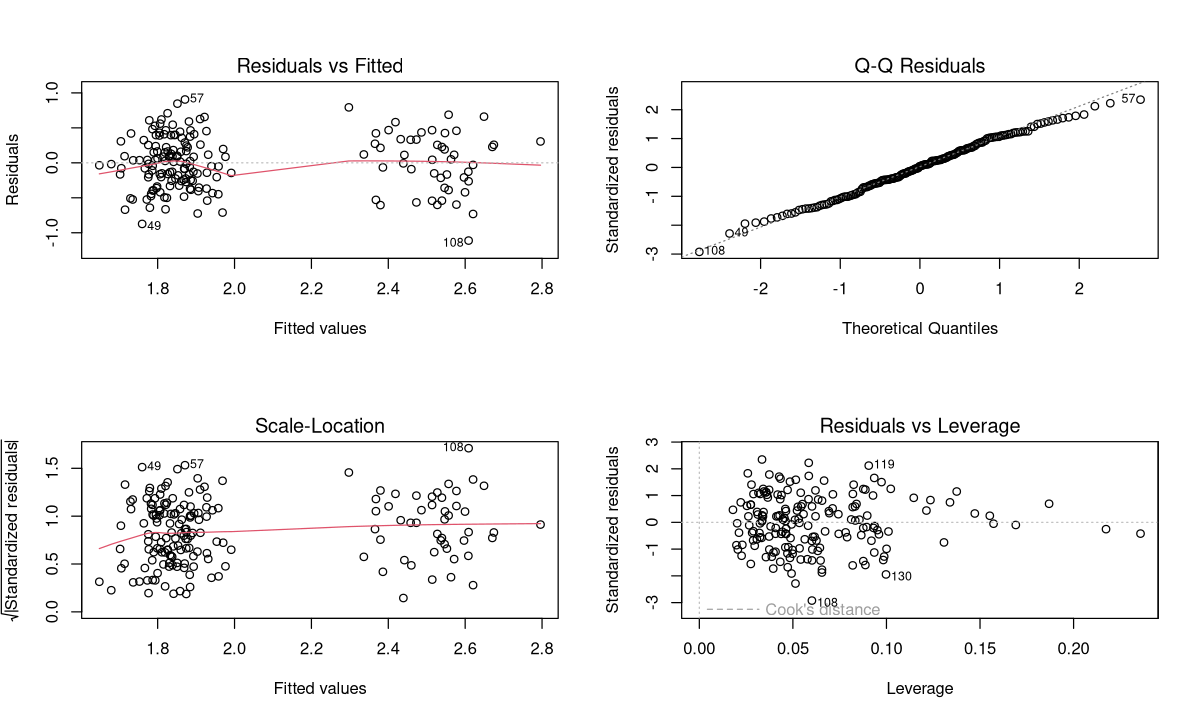

In [21]:
reg2b <- lm(log10(y) ~ x)
par(mfrow = c(2, 2)); plot(reg2b); par(mfrow = c(1, 1))
shapiro.test(resid(reg2b))

108        119        130 
0.04973649 0.04067752 0.03817153

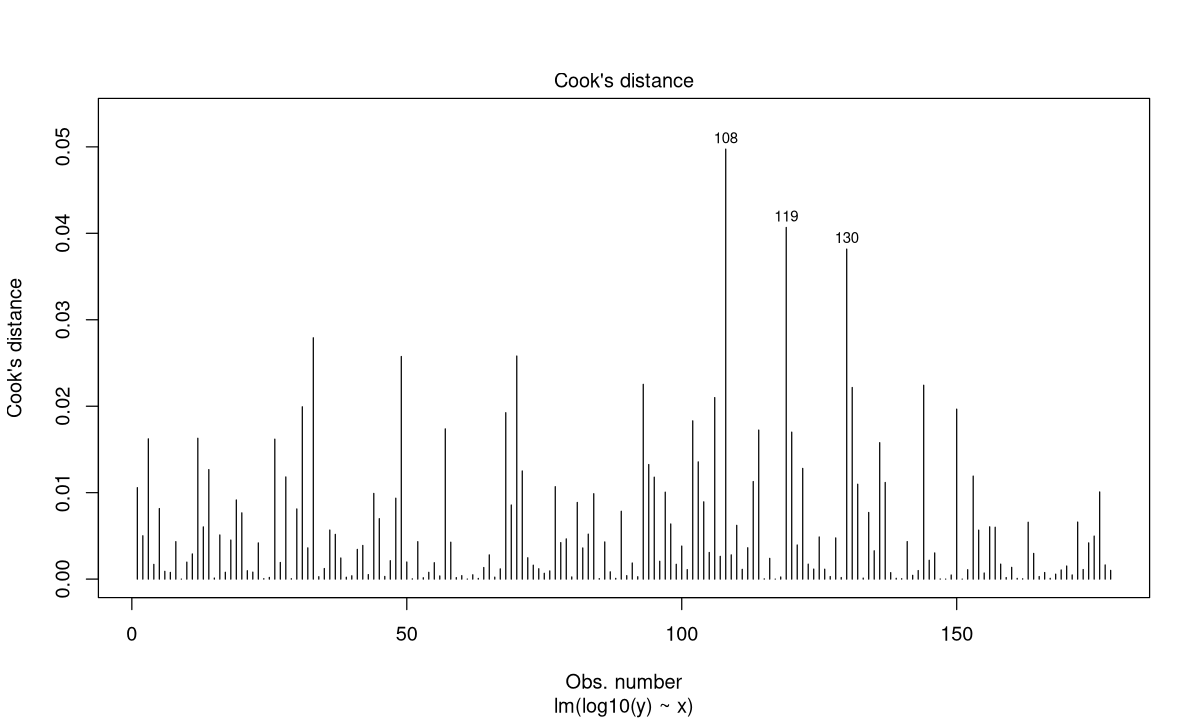

In [22]:
plot(reg2b, which = 4)
head(sort(cooks.distance(reg2b), decreasing = TRUE), 3)

Les résidus sont maintenant **normaux** (p = 0.66) et **homoscédastiques**. Trois échantillons ressortent encore par la distance de Cook : **108, 119 et 130**.

**Un « trou » dans les données** : sur le graphe *Residuals vs Fitted*, on remarque qu'**aucune valeur prédite** ne se situe entre **2 et 2.2** (log10 mg/L, soit ≈ 100 à 160 mg/L). Il y a donc un **trou dans l'échantillonnage** : il serait pertinent de **compléter le jeu de données** par un échantillonnage supplémentaire dans cette zone.


(1.6,1.7] (1.7,1.8] (1.8,1.9]   (1.9,2]   (2,2.1] (2.1,2.2] (2.2,2.3] (2.3,2.4] 
        2        37        70        21         0         0         1         7 
(2.4,2.5] (2.5,2.6] (2.6,2.7] (2.7,2.8] 
       10        21         8         1 

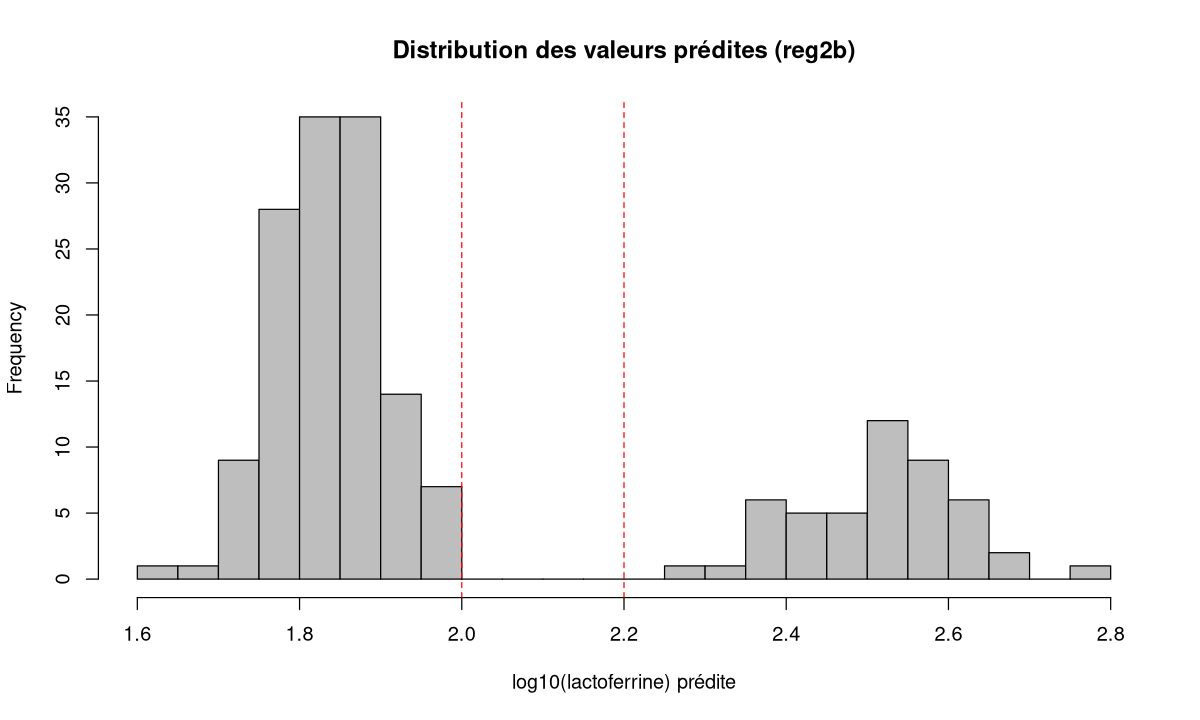

In [23]:
hist(fitted(reg2b), breaks = 30, col = "grey", main = "Distribution des valeurs prédites (reg2b)",
     xlab = "log10(lactoferrine) prédite")
abline(v = c(2, 2.2), col = "red", lty = 2)
table(cut(fitted(reg2b), breaks = seq(1.6, 2.8, 0.1)))

In [24]:
summary(reg2b)


Call:
lm(formula = log10(y) ~ x)

Residuals:
    Min      1Q  Median      3Q     Max 
-1.1116 -0.2576  0.0159  0.2696  0.9054 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)   
(Intercept)    1.8699     0.6354   2.943  0.00372 **
xV608         -0.1074     0.1119  -0.960  0.33865   
xV679         -0.8177     0.7204  -1.135  0.25802   
xV716       -129.6933   211.7133  -0.613  0.54098   
xV710        -14.9923    31.9794  -0.469  0.63982   
xV209         13.1232    24.6932   0.531  0.59581   
xV715        430.6284   561.2759   0.767  0.44403   
xV711        102.2438   128.9431   0.793  0.42894   
xV714       -654.0764   650.8133  -1.005  0.31634   
xV712       -312.2666   287.3592  -1.087  0.27875   
xV713        573.4580   487.1655   1.177  0.24082   
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.3922 on 167 degrees of freedom
Multiple R-squared:  0.4007,	Adjusted R-squared:  0.3649 
F-statistic: 11.17 on 10 and 167 DF, 

**Performances** : $R^2 = 0.4007$, $R^2_{adj} = 0.3649$, RSE = 0.3922 (log10). Nette amélioration par rapport à `reg1b` ($R^2$ = 0.284).

**Mais** : en observant les p-values, on constate qu'**aucune** variable n'est significative ! Et certains coefficients sont énormes (−654, +573…) avec des erreurs standards encore plus grandes. Pourtant, prise **séparément**, chacune de ces variables est très significative (partie 2 : V713 seule a $p = 10^{-14}$).

**Explication** : une **même information** est partagée par plusieurs variables → c'est la **colinéarité**.

### Exercice 3.4 : un modèle avec seulement V713 et V712
Ajuste `lm(log10(y) ~ x[, c("V712", "V713")])`. Compare les coefficients et p-values à ceux de `reg1b` (V713 seule, coefficient 6.37, p ≈ 2e-14). Que se passe-t-il ?

In [25]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
m_2 <- lm(log10(y) ~ x[, c("V712", "V713")])
summary(m_2)$coefficients
cor(x[, "V712"], x[, "V713"])
```

Avec V712 et V713 ensemble (corrélation ≈ 0.99), les coefficients deviennent instables (grands, de signes opposés) et les erreurs standards explosent : aucune des deux n'est plus significative, alors que chacune l'est seule. Le $R^2$, lui, ne bouge presque pas : la 2e variable n'apporte quasiment **aucune information nouvelle**.

</details>

---
## 3.6 La colinéarité dans les données spectrales

> **Définition** : il y a **colinéarité** quand des variables explicatives sont **fortement corrélées** entre elles, c'est-à-dire qu'elles partagent la même information. Elle n'est pas gérée par toutes les méthodes de Machine Learning ; on peut être amené à **supprimer** des variables trop corrélées.

Regardons la matrice de corrélation entre les 10 explicatives :

In [26]:
corr2 <- cor(x)
kable(corr2, digits = 2)



|     |  V608|  V679|  V716|  V710|  V209|  V715|  V711|  V714|  V712|  V713|
|:----|-----:|-----:|-----:|-----:|-----:|-----:|-----:|-----:|-----:|-----:|
|V608 |  1.00|  0.08| -0.16| -0.18| -0.24| -0.20| -0.23| -0.24| -0.26| -0.26|
|V679 |  0.08|  1.00| -0.07|  0.08| -0.15| -0.11| -0.06| -0.15| -0.15| -0.18|
|V716 | -0.16| -0.07|  1.00|  0.57|  0.76|  0.98|  0.66|  0.89|  0.71|  0.78|
|V710 | -0.18|  0.08|  0.57|  1.00|  0.38|  0.66|  0.94|  0.73|  0.84|  0.77|
|V209 | -0.24| -0.15|  0.76|  0.38|  1.00|  0.74|  0.49|  0.69|  0.56|  0.62|
|V715 | -0.20| -0.11|  0.98|  0.66|  0.74|  1.00|  0.78|  0.97|  0.84|  0.89|
|V711 | -0.23| -0.06|  0.66|  0.94|  0.49|  0.78|  1.00|  0.88|  0.97|  0.93|
|V714 | -0.24| -0.15|  0.89|  0.73|  0.69|  0.97|  0.88|  1.00|  0.95|  0.98|
|V712 | -0.26| -0.15|  0.71|  0.84|  0.56|  0.84|  0.97|  0.95|  1.00|  0.99|
|V713 | -0.26| -0.18|  0.78|  0.77|  0.62|  0.89|  0.93|  0.98|  0.99|  1.00|

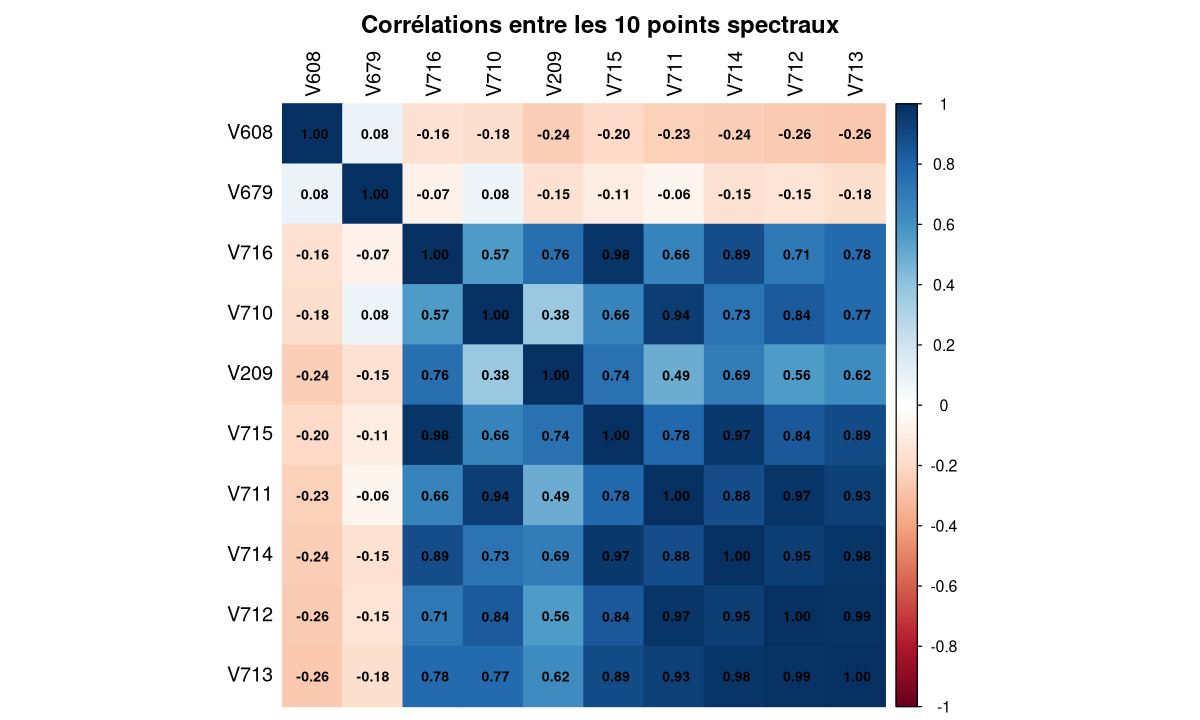

In [27]:
corrplot(corr2, method = "color", addCoef.col = "black", number.cex = 0.7,
         tl.col = "black", title = "Corrélations entre les 10 points spectraux", mar = c(0, 0, 2, 0))

Les corrélations sont **très élevées entre points spectraux proches** (V712-V713 : 0.99 ; V715-V716 : 0.98 ; V714-V713 : 0.98…). C'est attendu : la fréquence du signal infrarouge change très peu entre deux points adjacents ; on observe donc **plus ou moins les vibrations des mêmes molécules**. V608 et V679, éloignés, sont peu corrélés aux autres.

> **Complément — le VIF** (*Variance Inflation Factor*) quantifie la colinéarité de chaque variable : $VIF_j = \dfrac{1}{1 - R_j^2}$, où $R_j^2$ est le $R^2$ de la régression de $x_j$ sur toutes les autres explicatives. $VIF = 1$ : aucune colinéarité ; $VIF > 10$ : colinéarité problématique. Fonction `car::vif()` (le modèle doit être écrit avec un `data.frame`, pas une matrice).

In [28]:
df10 <- data.frame(ly = log10(y[, 1]), x)
round(vif(lm(ly ~ ., data = df10)))

V608   V679   V716   V710   V209   V715   V711   V714   V712   V713 
     1      1   9892   2951      3 119634  51300 358701 253033 462435

Des VIF de l'ordre de $10^4$ à $10^5$ : la variance des coefficients est « gonflée » d'un facteur énorme, ce qui explique les erreurs standards gigantesques de `reg2b`.

**Solutions** (vues dans la suite du cours) :
- **sélectionner** un sous-ensemble de variables (partie 4 : all-possible, backward, forward, stepwise) ;
- **pénaliser** les coefficients (partie 6 : Ridge, Lasso, Elastic Net) ;
- **réduire la dimension** de X (module 2 : PCR, PLS).

### Exercice 3.5 : la paire la plus colinéaire
À partir de `corr2`, trouve automatiquement la paire de variables (différentes) la plus corrélée. *Indice* : remplace la diagonale par `NA` (`diag(m) <- NA`), puis utilise `which(..., arr.ind = TRUE)`.

In [29]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
m <- abs(corr2)
diag(m) <- NA
pos <- which(m == max(m, na.rm = TRUE), arr.ind = TRUE)
rownames(m)[pos[1, ]]; max(m, na.rm = TRUE)
```

La paire la plus corrélée est V712-V713 (r ≈ 0.99), deux points adjacents.

</details>

### Exercice 3.6 : calculer un VIF à la main
Calcule le VIF de V713 « à la main » : régression de V713 sur les 9 autres explicatives, puis $1/(1 - R^2)$. Compare avec `vif()`.

In [30]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
r2_713 <- summary(lm(x[, "V713"] ~ x[, colnames(x) != "V713"]))$r.squared
1 / (1 - r2_713)
```

On retrouve la valeur de `vif()` pour V713 (≈ 460 000) : V713 est presque parfaitement prédite par les autres points spectraux ($R^2_j$ ≈ 0.999998).

</details>

---
## 3.7 Précautions (syllabus §3.4)

1. **Nombre d'observations ≥ nombre de variables explicatives** (en réalité, il faut $n > q + 1$ pour estimer tous les coefficients et la variance résiduelle).
2. La régression linéaire est **sensible aux données extrêmes** : un contrôle de qualité des données est nécessaire **avant** toute modélisation (partie 1).
3. La **colinéarité** entre explicatives peut poser problème : elle doit être **détectée**. Autrement dit, les explicatives doivent être **linéairement indépendantes**.

Illustration de la précaution 1, d'abord sur des données **simulées** : 20 observations, 25 variables explicatives de **pur bruit**.

In [31]:
set.seed(5)
Z  <- matrix(rnorm(20 * 25), nrow = 20)     # 25 variables aléatoires
yy <- rnorm(20)                             # y sans aucun lien avec Z
m_np <- lm(yy ~ Z)
c(nb_coef_estimes = sum(!is.na(coef(m_np))), nb_coef_NA = sum(is.na(coef(m_np))),
  R2 = summary(m_np)$r.squared, df_residuels = m_np$df.residual)

nb_coef_estimes      nb_coef_NA              R2    df_residuels 
             20               6               1               0

Avec $q \ge n$ : seuls 20 coefficients (intercept compris) peuvent être estimés, les 6 autres valent NA ; le modèle passe **exactement** par tous les points ($R^2 = 1$, 0 degré de liberté résiduel) alors que y est du bruit ! C'est le sur-ajustement absolu : le modèle « apprend par cœur » et n'a **aucune** capacité de généralisation.

Et avec les données spectrales ? Mettons **200 points spectraux** pour 178 échantillons :

In [32]:
X200 <- as.matrix(lactoferrin[, 2:201])            # 200 variables, 178 observations
m200 <- lm(log10(y) ~ X200)
c(rang_X = qr(cbind(1, X200))$rank, nb_coef_estimes = sum(!is.na(coef(m200))),
  nb_coef_NA = sum(is.na(coef(m200))), R2 = summary(m200)$r.squared, df_residuels = m200$df.residual)

rang_X nb_coef_estimes      nb_coef_NA              R2    df_residuels 
    167.0000000     167.0000000      34.0000000       0.9007024      11.0000000

Seuls **167** coefficients sont estimables : le **rang** de la matrice spectrale (167) est même inférieur au nombre d'échantillons (178) — les spectres contiennent des **dépendances linéaires exactes** entre points (colinéarité extrême, sans doute liée au prétraitement des spectres). Le $R^2$ grimpe à 0.90 avec seulement 11 degrés de liberté résiduels : un tel modèle serait totalement sur-ajusté.

### Exercice 3.7 : sensibilité aux extrêmes
Sur les données méthane, modifie **une seule** valeur de CH4 (par ex. multiplie la valeur de la vache 1 par 3, comme une erreur d'encodage) et réajuste `CH4 ~ FA4_6`. Compare la pente et le $R^2$ avant / après. Regarde le graphe de la distance de Cook.

In [33]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
meth_err <- methane
meth_err$CH4[1] <- meth_err$CH4[1] * 3
m_ok  <- lm(CH4 ~ FA4_6, data = methane)
m_err <- lm(CH4 ~ FA4_6, data = meth_err)
rbind(ok = c(coef(m_ok), R2 = summary(m_ok)$r.squared),
      erreur = c(coef(m_err), R2 = summary(m_err)$r.squared))
plot(m_err, which = 4)
```

Une seule valeur aberrante modifie fortement la pente (≈ 124 → 80) et fait chuter le $R^2$ (≈ 0.36 → 0.10) ; la distance de Cook de la vache 1 se détache nettement de toutes les autres. D'où l'importance du contrôle de qualité préalable.

</details>

---
## 3.8 Création de nouvelles variables (syllabus §3.7)

La création de nouvelles variables (*features*) est très courante en Machine Learning.

### 3.8.1 Régression polynomiale
Pour modéliser des courbes (ex. quadratiques — la slide « Regression : trend modeling »), on crée de nouvelles explicatives **à partir des explicatives initiales** : si $x_1 = \text{âge}$, on crée $x_2 = \text{âge}^2$, $x_3 = \text{âge}^3$. Le modèle reste **linéaire dans ses coefficients** :
$$y = b_0 + b_1\,\text{âge} + b_2\,\text{âge}^2 + b_3\,\text{âge}^3 + e$$

La **standardisation** est très importante ici, vu les échelles très différentes créées par les exposants (âge ≈ 50, âge³ ≈ 125 000).

> **Fonction R** : dans une formule, `I(x^2)` crée la variable $x^2$ (sans `I()`, `^` a un autre sens dans les formules). `poly(x, degree, raw = TRUE)` crée d'un coup $x, x^2, \dots, x^d$ ; avec `raw = FALSE` (défaut), il crée des **polynômes orthogonaux** (non corrélés entre eux, numériquement plus stables) — mêmes prédictions, coefficients différents.

R2_lineaire R2_quadratique 
    0.06619746     0.74253696

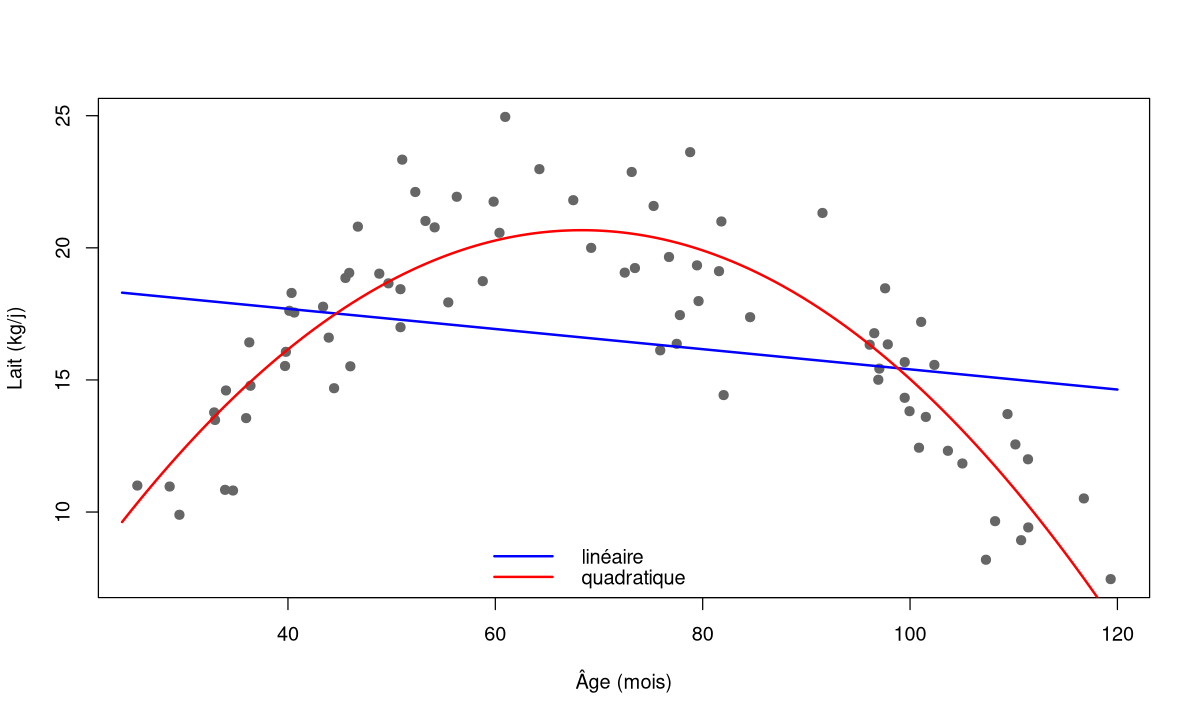

In [34]:
# Exemple simulé : production laitière (kg/j) en fonction de l'âge (mois) - relation en cloche
set.seed(3)
age <- runif(80, 24, 120)
lait <- -10 + 0.9 * age - 0.0065 * age^2 + rnorm(80, 0, 2.5)

m_lin  <- lm(lait ~ age)
m_quad <- lm(lait ~ age + I(age^2))
c(R2_lineaire = summary(m_lin)$r.squared, R2_quadratique = summary(m_quad)$r.squared)

plot(age, lait, pch = 19, col = "grey40", xlab = "Âge (mois)", ylab = "Lait (kg/j)")
g <- seq(24, 120, length.out = 200)
lines(g, predict(m_lin,  data.frame(age = g)), col = "blue", lwd = 2)
lines(g, predict(m_quad, data.frame(age = g)), col = "red",  lwd = 2)
legend("bottom", c("linéaire", "quadratique"), col = c("blue", "red"), lwd = 2, bty = "n")

In [35]:
# Pourquoi standardiser ? Les termes polynomiaux bruts sont très colinéaires et d'échelles différentes
round(cor(cbind(age, age2 = age^2, age3 = age^3)), 4)
age_s <- as.vector(scale(age))            # autoscaling (partie 1)
round(cor(cbind(age_s, age_s2 = age_s^2, age_s3 = age_s^3)), 4)
summary(lm(lait ~ age + I(age^2) + I(age^3)))$coefficients[, 1:2]

,age,age2,age3
age,1.0000,0.9887,0.9622
age2,0.9887,1.0000,0.9919
age3,0.9622,0.9919,1.0000


,age_s,age_s2,age_s3
age_s,1.0000,0.1543,0.9136
age_s2,0.1543,1.0000,0.2262
age_s3,0.9136,0.2262,1.0000


,Estimate,Std. Error
(Intercept),-1.618967e+01,4.8369913016
age,1.300486e+00,0.2318665276
I(age^2),-1.366257e-02,0.0034216287
I(age^3),3.733984e-05,0.0000157859


Les termes bruts âge, âge², âge³ sont corrélés à plus de 0.97 et leurs coefficients sont d'ordres de grandeur très différents ; après centrage-réduction, la corrélation entre $x$ et $x^2$ disparaît presque.

### 3.8.2 Combinaisons de variables (interactions, ratios)
On peut aussi créer de nouvelles variables en **combinant** des explicatives entre elles : produit (interaction), ratio, somme…

| Formule | Modèle |
|---|---|
| `y ~ x1 + x2 + x1:x2` ou `y ~ x1 * x2` | effets principaux + interaction $x_1 x_2$ |
| `y ~ I(x1 / x2)` | ratio |
| `y ~ I(x1 + x2)` | somme (une seule variable) |

In [36]:
# Exemple : interaction entre deux groupes d'acides gras (données méthane simulées)
m_int <- lm(CH4 ~ FA4_6 * FA7_9, data = methane)
summary(m_int)$coefficients

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),35.93313,1348.6463,0.02664385,0.9790733
FA4_6,-44.80683,306.1952,-0.14633422,0.8854854
FA7_9,122.48112,1310.8221,0.09343840,0.9267153
FA4_6:FA7_9,112.89596,293.8256,0.38422778,0.7058681


Ici l'interaction n'est pas significative (et la simulation n'en contenait pas). Remarque : le terme $x_1 x_2$ est lui-même très corrélé à $x_1$ et $x_2$ → les erreurs standards de tous les coefficients explosent ; centrer les variables avant de créer l'interaction limite ce problème.

### Exercice 3.8 : polynôme de degré 3 et polynômes orthogonaux
1. Ajuste sur `age`/`lait` le modèle de degré 3 avec `poly(age, 3, raw = TRUE)` puis avec `poly(age, 3)` (orthogonal).
2. Vérifie que les **prédictions** sont identiques mais que les coefficients diffèrent.
3. Le terme de degré 3 est-il utile ? (regarde sa p-value et le $R^2$ ajusté par rapport à `m_quad`)

In [37]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
m3_raw  <- lm(lait ~ poly(age, 3, raw = TRUE))
m3_orth <- lm(lait ~ poly(age, 3))
all.equal(fitted(m3_raw), fitted(m3_orth))      # TRUE : mêmes prédictions
coef(m3_raw); coef(m3_orth)                      # coefficients différents
summary(m3_orth)$coefficients
c(adjR2_quad = summary(m_quad)$adj.r.squared, adjR2_cub = summary(m3_raw)$adj.r.squared)
```

Le terme cubique n'est pas significatif (la vraie relation simulée est quadratique) et le $R^2$ ajusté n'augmente pas : on garde le modèle quadratique, plus **parcimonieux**.

</details>

### Questions de compréhension

**Q1.** Pourquoi la première colonne de $X$ est-elle remplie de 1 ?

**Q2.** Dans `reg2b`, aucune variable n'est significative mais le $R^2$ vaut 0.40 et le test F global est très significatif. Est-ce contradictoire ?

**Q3.** Deux modèles ont exactement le même $R^2$ et le même RMSE de calibration. Peut-on en conclure qu'ils s'interprètent de la même façon ?

**Q4.** Vrai ou faux : « un $R^2$ de calibration de 0.99 garantit que le modèle prédira bien de nouveaux échantillons ».

**Q5.** Pourquoi des points spectraux adjacents sont-ils si corrélés ?

<details>
<summary><b>Voir les réponses</b></summary>

**Q1.** Elle multiplie l'intercept $b_0$ : la ligne $i$ du produit $X\beta$ vaut $1 \times b_0 + b_1 x_{i,1} + \dots$

**Q2.** Non. Le test F global teste « au moins un coefficient ≠ 0 » : les 10 variables **ensemble** expliquent bien y. Les tests t individuels testent l'apport de chaque variable **en plus de toutes les autres** : comme l'information est partagée (colinéarité), aucune n'apporte rien d'**unique**. C'est la signature typique de la colinéarité.

**Q3.** Non (exemple méthane 3.4) : en cas de colinéarité, des modèles aux performances identiques peuvent avoir des coefficients complètement différents.

**Q4.** Faux : un $R^2$ de calibration très élevé peut signaler un **sur-ajustement**. Seule la **validation** sur des données indépendantes renseigne sur la capacité de généralisation.

**Q5.** La fréquence du signal infrarouge varie très peu d'un point au suivant : les deux points mesurent l'absorption des **mêmes liaisons moléculaires** (mêmes vibrations), donc leurs valeurs évoluent ensemble d'un échantillon à l'autre.

</details>

---
## Récapitulatif

**Points clés**
- Modèle multivarié : $y = X\beta + e$, $X$ = matrice d'incidence avec une colonne de 1.
- OLS : $\min (y - X\beta)^2$ → $X'X\beta = X'y$ → $\hat\beta = (X'X)^{-1}X'y$ ; l'inversion est **problématique** en cas de colinéarité ou si $n \le q$.
- $MSE = \frac{1}{n-p}\sum e_i^2$ (p paramètres estimés) ; R² augmente **toujours** avec le nombre de variables → R² ajusté, et surtout **validation** sur données indépendantes (RMSEP).
- **Sur-ajustement** : le modèle explique une variabilité propre au jeu de calibration.
- **Colinéarité** : parfaite (somme = 100 % → NA, singularities) ou forte (spectres adjacents → coefficients instables, non significatifs, VIF énormes). Mêmes performances ≠ même interprétation.
- Lactoferrine, 10 points les plus corrélés : `reg2b` (log10) → R² 0.4007, R² ajusté 0.3649, résidus normaux, Cook 108/119/130, trou de 2 à 2.2 dans les prédictions, **aucun coefficient significatif**.
- Précautions : n ≥ p, données extrêmes, colinéarité.
- Nouvelles variables : polynômes (`I(x^2)`, `poly`), interactions (`x1*x2`), **standardiser**.

**Fonctions R vues**

| Fonction | Usage |
|---|---|
| `cbind(1, X)`, `t()`, `%*%`, `crossprod()`, `solve()` | calcul matriciel de $\hat\beta$ |
| `qr(X)$rank`, `kappa()` | rang / conditionnement de X |
| `lm(y ~ X)` (X matrice), `lm(y ~ ., data)` | régression multivariée |
| `cor(x)`, `kable()`, `corrplot()` | matrice de corrélation et visualisation |
| `car::vif()` | facteurs d'inflation de variance (complément) |
| `poly()`, `I()`, `x1 * x2` | polynômes, interactions |
| `sapply()`, `lapply()`, `tryCatch()` | automatiser plusieurs modèles / capturer une erreur |

**Partie suivante** : `04_Selection_de_variables.ipynb` — choisir le meilleur sous-ensemble parmi les 10 points spectraux (all-possible, backward, forward, stepwise) et mesurer l'importance relative des variables.